<a href="https://colab.research.google.com/github/xyosho/Proyecto-Homologacion-ML/blob/Sprint-2/sprint2_caracteristicas_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sprint 2 — Ingeniería de características y modelo base
**Proyecto:** Modelo Predictivo de Segmentación de Mercado y Propensión a la Matrícula · Unicervantes

**Pedido del docente (Semana 2):** entregar *la misma tabla de datos con columnas nuevas y útiles* (por ejemplo,
"¿Aplica a Beca Mi Vocación? Sí/No" o "Promedio estimado"; también `probabilidad_acceso_beca` y
`segmento_rendimiento_icfes`) y *un cálculo muy sencillo (modelo base) que sirva de punto de comparación*.

| Sección | Contenido |
|---|---|
| 1 | Datos y partición temporal (entrenamiento, validación, prueba y campaña) |
| 2 | Lo que se aprende SOLO del entrenamiento (sin fuga de datos) |
| 3 | Las 15 columnas nuevas |
| 4 | Segmentación de mercado con k-means |
| 5 | Relación de las columnas nuevas con la matrícula |
| 6 | Modelo base y su error |

## Antes de empezar (Google Colab)
Las credenciales **no** se escriben en ninguna celda; se guardan en los **Secretos** de Colab:

1. Abra el panel **Secretos** (icono de llave, a la izquierda).
2. Cree `SUPABASE_URL` (la URL del proyecto, `https://….supabase.co`) y `SUPABASE_KEY` (la clave **publicable**,
   `sb_publishable_…`; nunca la secreta).
3. Active **Acceso del notebook** en los dos secretos.
4. Ejecute todo: *Entorno de ejecución → Ejecutar todas*. Si aparece un aviso para dar acceso a los secretos, acéptelo.

Las celdas que empiezan con `%%writefile` crean en Colab una copia exacta del código del repositorio (carpeta `src/`).

In [ ]:
!pip -q install supabase==2.33.0 xgboost==3.4.1 shap==0.54.1 lime==0.2.0.1

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
%%writefile comun.py
"""Versión para Google Colab de src/comun.py: la configuración del proyecto (config/reglas_negocio.yaml)
viene incrustada porque Colab no tiene el repositorio. Generado por src/s06_construir_cuadernos.py."""
from pathlib import Path

RAIZ = Path.cwd()
DATA_PROCESSED = RAIZ / "data" / "processed"

_CONFIG = {'campus': {'nombre': 'Campus Unicervantes',
            'direccion': 'Calle 209 No. 104-15, vía Arrayanes, Bogotá',
            'lat': 4.790438,
            'lon': -74.066288,
            'fuente': 'Dirección: Acuerdo 002/2025 (membrete). Coordenada exacta de la placa Calle 209 # '
                      '104-15 (CL 209 104 15, lote 009140001001) en Placa Domiciliaria de Catastro Bogotá '
                      '(UAECD), consultada 23-oct-2026. Antes se usaba una coordenada aproximada de '
                      'OpenStreetMap (4.7895, -74.0660), a unos 100 m.'},
 'tarifas': {'AD': {2024: {'valor': 4419000,
                           'fuente': 'Precio de matrícula según recibos de pago: orden de pago Pregrado '
                                     "2024-2, concepto 'MAT ING ANALITICA DE DATOS NUEVOS'."},
                    2025: {'valor': 4658000,
                           'fuente': 'Precio de matrícula según recibos de pago 2025-1 y 2025-2: $3.260.600 '
                                     'con beca del 30% => 3.260.600 / 0,70; coincide con la versión 2025 de '
                                     'la página del programa.'},
                    2026: {'valor': 4914000,
                           'fuente': 'Acuerdo 002 del 11 de noviembre de 2025 del Consejo Directivo, art. 2 '
                                     '(valores de matrícula 2026).'},
                    2027: {'valor': 4914000,
                           'fuente': 'supuesto: S-01 (se mantiene el valor vigente hasta que se publique el '
                                     'acuerdo 2027).'}},
             'SSIA': {2026: {'valor': 4950000,
                             'fuente': 'Oferta académica oficial '
                                       'unicervantes.edu.co/admision/oferta-academica (consultada '
                                       '19-oct-2026).'},
                      2027: {'valor': 4950000, 'fuente': 'supuesto: S-01.'}}},
 'becas': {'SABER_11': {'nombre': 'Beca Saber 11',
                        'umbral_icfes': 310,
                        'pct_primer_periodo': 0.3,
                        'pct_siguientes': 0.3,
                        'promedio_minimo': 4.0,
                        'fuente': "Página oficial de Admisiones: 'Puntaje igual o superior a 310 ... 30% "
                                  "para toda la carrera por promedio académico'."},
           'MI_VOCACION': {'nombre': 'Beca Cervantes #MiVocación',
                           'pct_primer_periodo': 0.3,
                           'pct_siguientes': 0.2,
                           'promedio_minimo': 4.0,
                           'fuente': "Admisiones ('30% para el primer periodo académico y en adelante según "
                                     "la tabla relacionada'; se mantiene con promedio acumulado >= 4.0 y se "
                                     "pierde por sanciones); landing del programa ('30% 1er semestre y 20% "
                                     "el resto de la carrera')."},
           'NINGUNA': {'nombre': 'Sin beca',
                       'pct_primer_periodo': 0.0,
                       'pct_siguientes': 0.0,
                       'promedio_minimo': None},
           'acumulables': False},
 'particion': {'entrenamiento': ['2024-1', '2024-2', '2025-1', '2025-2'],
               'validacion': ['2026-1'],
               'prueba': ['2026-2'],
               'campana': ['2027-1']},
 'caracteristicas': {'bandas_icfes': [{'desde': 0, 'hasta': 250, 'segmento': 'BAJO'},
                                      {'desde': 250, 'hasta': 310, 'segmento': 'MEDIO'},
                                      {'desde': 310, 'hasta': 350, 'segmento': 'ALTO'},
                                      {'desde': 350, 'hasta': 501, 'segmento': 'SUPERIOR'}],
                     'zonas_distancia_km': {'CERCA': 10, 'MEDIA': 20},
                     'canal_agrupado': {'EVENTO': ['EXPOESTUDIANTES', 'CAMPUS_DAY'],
                                        'RELACIONAL': ['REFERIDO', 'INMERSION', 'COLEGIO_CONVENIO'],
                                        'DIGITAL': ['SITIO_WEB', 'REDES_SOCIALES', 'LLAMADA_WHATSAPP']},
                     'estrato_grupo': {1: 'BAJO', 2: 'BAJO', 3: 'MEDIO', 4: 'ALTO', 5: 'ALTO', 6: 'ALTO'},
                     'peso_previo_modelo_base': 10,
                     'kmeans': {'k_min': 3,
                                'k_max': 7,
                                'tolerancia_silueta': 0.01,
                                'semilla': 20261029,
                                'variables': ['estrato',
                                              'log_distancia',
                                              'punt_global',
                                              'promedio_acumulado_colegio',
                                              'edad_al_inscribirse',
                                              'colegio_privado']}},
 'modelado': {'semilla': 20261105,
              'umbral_clasificacion': 0.5,
              'segmentos_propension': {'ALTA': 0.6, 'BAJA': 0.35},
              'grillas': {'logistica': {'C': [0.01, 0.1, 1.0, 10.0]},
                          'random_forest': {'max_depth': [4, 6, 8, None],
                                            'min_samples_leaf': [5, 20],
                                            'max_features': ['sqrt', 0.5]},
                          'xgboost': {'n_estimators': [200, 400],
                                      'max_depth': [2, 3, 4],
                                      'learning_rate': [0.03, 0.1],
                                      'min_child_weight': [5]},
                          'random_forest_beca': {'max_depth': [3, 5, None],
                                                 'min_samples_leaf': [5, 15],
                                                 'max_features': ['sqrt', 0.5]},
                          'xgboost_beca': {'n_estimators': [150, 300],
                                           'max_depth': [2, 3],
                                           'learning_rate': [0.03, 0.1],
                                           'min_child_weight': [5]}}},
 'impacto': {'seguimiento': {'capacidad_pct': 0.3, 'efecto_maximo': 0.1, 'costo_por_inscrito': 30000},
             'expo': {'inversion_evento': 22000000},
             'beca': {'pct_marcado': 0.3,
                      'eficacia_tutoria': 0.25,
                      'costo_tutoria': 400000,
                      'semestres_restantes': 7}},
 'escala_desempeno_bachillerato': {'SUPERIOR': 4.6, 'ALTO': 4.0, 'BASICO': 3.0},
 'fondos_educacion_municipal': {'FOES_CHIA': {'ubicacion_id': 25175,
                                              'nombre': 'FOES - Fondo para el Fomento de la Educación '
                                                        'Superior de Chía',
                                              'norma': 'Acuerdo 172 de 2020; Resolución 2114 de 2021',
                                              'convenio_unicervantes': 'VERIFICADO',
                                              'apoyo_semestral_cop': 1000000,
                                              'requisitos': 'Residente de Chía (certificado de la JAC), '
                                                            'registro en el SISBÉN de Chía, certificado de '
                                                            'notas, Saber 11 y recibo de matrícula',
                                              'renovacion': 'Cada semestre (abril a octubre) según el '
                                                            'promedio del semestre anterior fijado en el '
                                                            'convenio',
                                              'fuente': 'Alcaldía de Chía (2022). Conozca el programa FOES: '
                                                        'Unicervantes en convenio (n.º 15); apoyo educativo '
                                                        'desde $1.000.000 en carreras presenciales.',
                                              'url': 'https://www.chia-cundinamarca.gov.co/2022/educacion/PROGRAMA%20FOES%20ACTUALIZADO%2022-09-2022.pdf'},
                                'FOES_SOPO': {'ubicacion_id': 25758,
                                              'nombre': 'FOES - Fondo Especial para el Fomento de la '
                                                        'Educación de Sopó',
                                              'norma': 'No publicada en la página consultada',
                                              'convenio_unicervantes': 'NO_VERIFICADO',
                                              'apoyo_semestral_cop': 1000000,
                                              'requisitos': 'Residente de Sopó, admitido o matriculado en un '
                                                            'programa de educación superior',
                                              'renovacion': 'No publicada',
                                              'fuente': 'Alcaldía de Sopó (2022, actualizado 2026). FOES: '
                                                        'apoyo de matrícula, transporte y sostenimiento. '
                                                        'Monto: supuesto S-31.',
                                              'url': 'https://www.sopo-cundinamarca.gov.co/educacion/publicaciones/290/foes-fondo-especial-para-el-fomento-de-la-educacion/'},
                                'FOEST_TOCANCIPA': {'ubicacion_id': 25817,
                                                    'nombre': 'FOEST - Fondo Especial de Educación Superior '
                                                              'de Tocancipá',
                                                    'norma': 'Aprobado por el Concejo Municipal (acuerdo no '
                                                             'consultado)',
                                                    'convenio_unicervantes': 'NO_VERIFICADO',
                                                    'apoyo_semestral_cop': 1000000,
                                                    'requisitos': 'Residente de Tocancipá; becas para '
                                                                  'mejores puntajes Saber 11, artistas y '
                                                                  'deportistas; descuentos por convenio',
                                                    'renovacion': 'No publicada',
                                                    'fuente': 'Alcaldía de Tocancipá (2017). $1.750 millones '
                                                              'para la educación superior. Monto por '
                                                              'estudiante: supuesto S-31.',
                                                    'url': 'https://www.tocancipa-cundinamarca.gov.co/sala-prensa/noticias-1/1-750-millones-para-educacion-superior-tocancipa'}},
 'inversion_captacion': {'por_evento': {'EXPOESTUDIANTES': 22000000, 'CAMPUS_DAY': 6000000},
                         'por_periodo': {'SITIO_WEB': {'1': 9000000, '2': 6000000},
                                         'REDES_SOCIALES': {'1': 18000000, '2': 10000000},
                                         'LLAMADA_WHATSAPP': {'1': 8000000, '2': 6000000},
                                         'COLEGIO_CONVENIO': {'1': 7000000, '2': 4000000},
                                         'INMERSION': {'1': 5000000, '2': 5000000},
                                         'REFERIDO': {'1': 3000000, '2': 3000000}},
                         'ventana_campana': {'1': ['03-01', '01-25'], '2': ['01-10', '07-25']}},
 'generador': {'matricula': {'tasa_objetivo': 0.45,
                             'beta_descuento': 3.0,
                             'beta_estrato': {1: -0.5, 2: -0.15, 3: 0.0, 4: 0.1, 5: 0.0, 6: -0.3},
                             'beta_log_distancia': -0.35,
                             'beta_icfes_cuadratico': -0.25,
                             'beta_canal': {'EXPOESTUDIANTES': -0.3,
                                            'SITIO_WEB': 0.0,
                                            'REDES_SOCIALES': -0.1,
                                            'REFERIDO': 0.5,
                                            'CAMPUS_DAY': 0.3,
                                            'LLAMADA_WHATSAPP': -0.2,
                                            'INMERSION': 0.8,
                                            'COLEGIO_CONVENIO': 0.3},
                             'beta_entrevista': 0.6,
                             'beta_programa_ssia': 0.1,
                             'beta_periodo_2': -0.1,
                             'beta_foes': 0.5},
               'desercion': {'riesgo_base': {1: 0.12, 2: 0.08, 3: 0.05},
                             'multiplicador_promedio_bajo': 2.5,
                             'multiplicador_perdio_beca': 1.5}}}


def cargar_config() -> dict:
    return _CONFIG


Writing comun.py


In [ ]:
%%writefile conexion_supabase.py
"""Conexión SEGURA de Python con Supabase para leer la tabla plana dataset_matricula.

Las credenciales NUNCA se escriben en el código ni se imprimen:
  - En el computador: archivo .env en la raíz del proyecto, excluido por .gitignore (plantilla: .env.example).
    Se puede crear con:  python src/s00_configurar_credenciales.py
  - En Google Colab: panel "Secretos" (icono de llave) con SUPABASE_URL y SUPABASE_KEY, con acceso al cuaderno.

SUPABASE_KEY es la clave PUBLICABLE del proyecto. En la base, la seguridad a nivel de fila (RLS) solo le permite
LEER dataset_matricula (sin datos personales); las otras 25 tablas están cerradas y nadie puede escribir con ella.
Así, aunque la clave se filtrara, solo se podría leer el dataset anonimizado.
"""
from __future__ import annotations

import os
from pathlib import Path

import pandas as pd

TABLA = "dataset_matricula"
VARIABLES = ("SUPABASE_URL", "SUPABASE_KEY")
TAMANO_PAGINA = 1000          # la API de Supabase entrega como máximo 1.000 filas por petición
TIEMPO_LIMITE_S = 30          # si la red no responde, se desiste en vez de quedarse esperando


def en_colab() -> bool:
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False


def obtener_credenciales() -> tuple[str, str]:
    """Devuelve (url, clave) desde los Secretos de Colab o desde .env / variables de entorno.

    En Colab, la primera vez que un cuaderno lee un secreto aparece un aviso para darle acceso: hay que aceptarlo
    (mientras no se acepte, la celda espera). Los errores explican qué falta, nunca muestran los valores.
    """
    problemas = []
    if en_colab():
        from google.colab import userdata
        valores = {}
        for v in VARIABLES:
            try:
                valores[v] = (userdata.get(v) or "").strip()
            except Exception as e:                  # SecretNotFoundError / NotebookAccessError
                valores[v] = ""
                motivo = ("el cuaderno no tiene acceso: active 'Acceso del notebook'" if "Access" in type(e).__name__
                          else "no existe un secreto con ese nombre exacto")
                problemas.append(f"{v}: {motivo}")
        donde = "los Secretos de Colab (icono de llave, con 'Acceso del notebook' activado)"
    else:
        from dotenv import load_dotenv
        load_dotenv(Path(__file__).resolve().parents[1] / ".env")
        valores = {v: os.environ.get(v, "").strip() for v in VARIABLES}
        donde = "el archivo .env (python src/s00_configurar_credenciales.py o copia de .env.example)"
    problemas += [f"{v}: está vacío" for v, x in valores.items() if not x and not any(p.startswith(v) for p in problemas)]
    url, clave = valores["SUPABASE_URL"], valores["SUPABASE_KEY"]
    if url and not (url.startswith("https://") and url.rstrip("/").endswith(".supabase.co")):
        problemas.append("SUPABASE_URL: no es la URL del proyecto (debe ser https://<proyecto>.supabase.co; "
                         "no la cadena postgresql:// del pooler)")
    if clave.lower().startswith(("postgres://", "postgresql://")):
        problemas.append("SUPABASE_KEY: es la cadena del pooler; aquí va la clave PUBLICABLE (sb_publishable_...)")
    elif clave.startswith("sb_secret_"):
        problemas.append("SUPABASE_KEY: es la clave SECRETA; use la PUBLICABLE (sb_publishable_...)")
    if problemas:
        raise RuntimeError(f"Credenciales incompletas en {donde}: " + "; ".join(problemas) + ".")
    return url, clave


def crear_cliente(url: str | None = None, clave: str | None = None):
    """Cliente de la API de Supabase con tiempo límite. La clave se usa en memoria y no se muestra."""
    from supabase import ClientOptions, create_client
    if url is None or clave is None:
        url, clave = obtener_credenciales()
    return create_client(url, clave, options=ClientOptions(postgrest_client_timeout=TIEMPO_LIMITE_S))


def leer_dataset_matricula(cliente, tabla: str = TABLA) -> pd.DataFrame:
    """Lee la tabla completa en páginas de 1.000 filas (límite de la API), ordenada por inscripcion_id."""
    filas, inicio = [], 0
    while True:
        r = (cliente.table(tabla).select("*").order("inscripcion_id")
             .range(inicio, inicio + TAMANO_PAGINA - 1).execute())
        filas += r.data
        if len(r.data) < TAMANO_PAGINA:
            break
        inicio += TAMANO_PAGINA
    return pd.DataFrame(filas)


def probar_solo_lectura(cliente, tabla: str = TABLA) -> bool:
    """Intenta modificar la tabla con la clave publicable. Devuelve True si la base lo RECHAZA por permisos
    (código 42501 de PostgreSQL: permiso denegado). La fila -1 no existe, así que nada cambiaría de todos modos."""
    try:
        cliente.table(tabla).update({"punt_global": 0}).eq("inscripcion_id", -1).execute()
    except Exception as e:                           # APIError de la API de Supabase
        return getattr(e, "code", None) == "42501"
    return False


Writing conexion_supabase.py


In [ ]:
%%writefile datos.py
"""Carga de las tablas planas para los sprints 2 a 6.

Fuente preferida: Supabase con la API de solo lectura (credenciales en .env o en los Secretos de Colab, ver
conexion_supabase.py). Si no hay credenciales, se usan los CSV que exporta el pipeline (data/processed), que son
idénticos (las pruebas lo comprueban). La función siempre dice de dónde salieron los datos.
"""
from __future__ import annotations

from pathlib import Path

import pandas as pd

TABLAS = ("dataset_matricula", "dataset_permanencia", "resultado_campana_2027_1")   # el último solo en el Sprint 5
ENTEROS_CON_VACIOS = ("matriculado", "puntaje_vocacional", "perdio_beca_semestre_1", "matriculado_real")


def preparar_tipos(df: pd.DataFrame) -> pd.DataFrame:
    """La API devuelve JSON: se fijan los tipos para que local y Colab den exactamente lo mismo."""
    df = df.copy()
    for c in ENTEROS_CON_VACIOS:
        if c in df:
            df[c] = pd.to_numeric(df[c]).astype("Int64")
    for c in ("distancia_campus_km", "distancia_vial_km", "colegio_promedio_saber11", "promedio_acumulado_colegio",
              "promedio_matematicas_colegio", "pct_descuento_inicial", "promedio_semestre_1"):
        if c in df:
            df[c] = pd.to_numeric(df[c]).astype(float)
    if "asesor_id" in df:
        df["asesor_id"] = df["asesor_id"].astype(int)
    return df.sort_values("inscripcion_id").reset_index(drop=True)


def _csv_local(tabla: str) -> Path:
    from comun import DATA_PROCESSED
    if tabla == "resultado_campana_2027_1":       # "sobre sellado" desde la Semana 1 (data/processed/oculto)
        return DATA_PROCESSED / "oculto" / "resultado_2027_1_sellado.parquet"
    return DATA_PROCESSED / f"{tabla}.csv"


def cargar(tabla: str, fuente: str = "auto") -> tuple[pd.DataFrame, str]:
    """Devuelve (datos, origen). fuente: 'supabase', 'local' o 'auto' (Supabase si hay credenciales)."""
    if tabla not in TABLAS:
        raise ValueError(f"Tabla desconocida: {tabla}")
    if fuente in ("auto", "supabase"):
        try:
            from conexion_supabase import crear_cliente, leer_dataset_matricula
            df = leer_dataset_matricula(crear_cliente(), tabla=tabla)
            return preparar_tipos(df), "Supabase (API de solo lectura)"
        except Exception as error:
            if fuente == "supabase":
                raise
            aviso = type(error).__name__
    ruta = _csv_local(tabla)
    df = pd.read_parquet(ruta) if ruta.suffix == ".parquet" else pd.read_csv(ruta)
    origen = "CSV local exportado por el pipeline" + (f" (sin conexión a Supabase: {aviso})" if fuente == "auto" else "")
    return preparar_tipos(df), origen


Writing datos.py


In [ ]:
%%writefile caracteristicas.py
"""SPRINT 2 — Ingeniería de características: columnas nuevas y útiles sobre la tabla plana dataset_matricula.

Regla de oro contra la FUGA DE DATOS: todo lo que se APRENDE de los datos (tasas de acceso a beca, la regresión del
promedio, las medias para estandarizar y los grupos de k-means) se ajusta SOLO con el conjunto de ENTRENAMIENTO
(2024-1 a 2025-2) y después se aplica igual a validación, prueba, campaña y a cualquier aspirante nuevo (Sprint 6).
Si se ajustara con todos los datos, el modelo "vería" información del futuro y sus métricas serían optimistas.

Funciones principales:
  particion_temporal(periodo)                      -> ENTRENAMIENTO / VALIDACION / PRUEBA / CAMPANA
  ajustar_referencias(inscritos, permanencia)      -> lo aprendido del entrenamiento (un diccionario)
  construir_caracteristicas(inscritos, referencias) -> la misma tabla con las columnas nuevas
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

NUEVAS = [
    "particion", "aplica_beca_saber11", "aplica_beca_mi_vocacion", "probabilidad_acceso_beca",
    "segmento_rendimiento_icfes", "promedio_estimado_universidad", "brecha_colegio_vs_icfes",
    "ahorro_beca_primer_semestre", "log_distancia", "zona_distancia", "rezago_saber11",
    "canal_agrupado", "estrato_grupo", "colegio_privado", "segmento_mercado",
]

# Descripción de cada columna nueva (diccionario del Sprint 2)
DICCIONARIO = {
    "particion": "Conjunto temporal: ENTRENAMIENTO (2024-1 a 2025-2), VALIDACION (2026-1), PRUEBA (2026-2), CAMPANA (2027-1)",
    "aplica_beca_saber11": "Sí/No: puntaje global Saber 11 ≥ 310 (requisito de la Beca Saber 11)",
    "aplica_beca_mi_vocacion": "Sí/No: presentó entrevista y su puntaje vocacional es ≥ 3 (requisito de Mi Vocación)",
    "probabilidad_acceso_beca": "Probabilidad de recibir alguna beca según los requisitos que cumple (frecuencia histórica del entrenamiento, con suavizado de Laplace)",
    "segmento_rendimiento_icfes": "BAJO (< 250), MEDIO (250-309), ALTO (310-349: ya aplica a beca) o SUPERIOR (≥ 350)",
    "promedio_estimado_universidad": "Promedio esperado en el 1er semestre (regresión lineal con Saber 11, promedio del colegio y estrato bajo)",
    "brecha_colegio_vs_icfes": "z(promedio del colegio) − z(Saber 11): positivo = rinde más en el colegio que en el examen",
    "ahorro_beca_primer_semestre": "Cuánto le ahorra la beca en el 1er semestre (tarifa plena − precio neto), en COP",
    "log_distancia": "Logaritmo natural de la distancia por vías desde la dirección hasta el campus (S-44; reduce la cola larga)",
    "zona_distancia": "Distancia por vías desde la dirección: CERCA (≤ 10 km), MEDIA (10-20 km) o LEJOS (> 20 km)",
    "rezago_saber11": "INMEDIATO (presentó el Saber 11 el año anterior), UN_ANIO o DOS_O_MAS",
    "canal_agrupado": "EVENTO (Expo, Campus Day), RELACIONAL (referido, inmersión, convenio) o DIGITAL (web, redes, llamada)",
    "estrato_grupo": "BAJO (1-2), MEDIO (3) o ALTO (4-6)",
    "colegio_privado": "1 si el colegio es privado",
    "segmento_mercado": "Perfil del aspirante según k-means (segmentación de mercado), nombrado por sus rasgos principales",
}

ETIQUETAS_KMEANS = {   # (si el centro está por encima, si está por debajo) de la media del entrenamiento
    "estrato": ("estrato más alto", "estrato más bajo"),
    "log_distancia": ("viven lejos del campus", "viven cerca del campus"),
    "punt_global": ("buen puntaje ICFES", "puntaje ICFES bajo"),
    "promedio_acumulado_colegio": ("buenas notas en el colegio", "notas bajas en el colegio"),
    "edad_al_inscribirse": ("aspirantes mayores", "aspirantes más jóvenes"),
    "colegio_privado": ("colegio privado", "colegio público"),
    "colegio_promedio_saber11": ("colegio de alto nivel", "colegio de nivel bajo"),
}

# Nombres en español sencillo para tablas y gráficas (los nombres técnicos de las columnas no cambian)
NOMBRES_LEGIBLES = {
    "estrato": "Estrato promedio",
    "log_distancia": "Distancia por vías (km)",
    "distancia_vial_km": "Distancia por vías (km)",
    "punt_global": "Puntaje ICFES",
    "promedio_acumulado_colegio": "Notas del colegio (1 a 5)",
    "edad_al_inscribirse": "Edad (años)",
    "colegio_privado": "% de colegio privado",
    "colegio_promedio_saber11": "Nivel ICFES del colegio",
    "segmento_mercado": "Segmento de mercado",
    "segmento_rendimiento_icfes": "Puntaje ICFES",
    "aplica_beca_mi_vocacion": "¿Aplica a la beca Mi Vocación?",
    "aplica_beca_saber11": "¿Aplica a la beca Saber 11?",
    "canal_agrupado": "Canal por el que llegó",
    "zona_distancia": "Distancia al campus",
    "estrato_grupo": "Estrato",
    "rezago_saber11": "Tiempo desde el ICFES",
}

# El ICFES llama "oficial" al colegio público. Los datos y los modelos conservan el código OFICIAL; en todo texto que
# se muestra (explicaciones, gráficas, script de predicción) se dice "público".
NOMBRE_TIPO_COLEGIO = {"OFICIAL": "público", "PRIVADO": "privado", "TECNICO": "técnico"}


def tipo_colegio_codigo(valor: str) -> str:
    """Código de datos del tipo de colegio: acepta PUBLICO (o PÚBLICO) como sinónimo de OFICIAL."""
    v = str(valor).strip().upper().replace("Ú", "U").replace("É", "E")
    return "OFICIAL" if v == "PUBLICO" else v


def etiquetas_categorias(cfg: dict | None = None) -> dict:
    """Texto claro para los códigos de las columnas categóricas nuevas (p. ej. CERCA → "Cerca (hasta 10 km)")."""
    c = (cfg or configuracion())["caracteristicas"]
    z = c["zonas_distancia_km"]
    icfes = {b["segmento"]: (f"{b['segmento'].capitalize()} (menos de {b['hasta']})" if b["desde"] == 0 else
                             f"{b['segmento'].capitalize()} ({b['desde']} o más)" if b["hasta"] > 500 else
                             f"{b['segmento'].capitalize()} ({b['desde']} a {b['hasta'] - 1})") for b in c["bandas_icfes"]}
    return {
        "segmento_rendimiento_icfes": icfes,
        "zona_distancia": {"CERCA": f"Cerca (hasta {z['CERCA']} km)", "MEDIA": f"Media ({z['CERCA']} a {z['MEDIA']} km)",
                           "LEJOS": f"Lejos (más de {z['MEDIA']} km)"},
        "canal_agrupado": {"EVENTO": "Eventos (Expo, Campus Day)", "RELACIONAL": "Relacional (referido, convenio…)",
                           "DIGITAL": "Digital (web, redes, llamada)"},
        "estrato_grupo": {"BAJO": "Estratos 1 y 2", "MEDIO": "Estrato 3", "ALTO": "Estratos 4 a 6"},
        "rezago_saber11": {"INMEDIATO": "Sin pausa tras el colegio", "UN_ANIO": "1 año de pausa", "DOS_O_MAS": "2 años o más de pausa"},
        "aplica_beca_mi_vocacion": {"Sí": "Sí aplica", "No": "No aplica"},
        "aplica_beca_saber11": {"Sí": "Sí aplica", "No": "No aplica"},
    }


def tabla_segmentos(d: pd.DataFrame) -> pd.DataFrame:
    """Resumen de cada segmento de mercado con valores reales (no estandarizados), listo para leer o presentar."""
    m = d.assign(matriculado=d["matriculado"].astype(float))
    def resumen(g: pd.DataFrame) -> dict:
        return {"Inscritos": len(g), "% del total": len(g) / len(d) * 100,
                "% que se matriculó": g["matriculado"].mean() * 100, "Puntaje ICFES": g["punt_global"].mean(),
                "Notas del colegio (1 a 5)": g["promedio_acumulado_colegio"].mean(),
                "Distancia por vías (km)": g["distancia_vial_km"].mean(), "Estrato promedio": g["estrato"].mean(),
                "% de colegio público": (1 - g["colegio_privado"].mean()) * 100, "Edad (años)": g["edad_al_inscribirse"].mean()}
    t = pd.DataFrame({s: resumen(g) for s, g in m.groupby("segmento_mercado")}).T
    t.loc["Todos los inscritos"] = resumen(m)
    t.index.name = "Segmento de mercado"
    return t.round({"Inscritos": 0, "% del total": 1, "% que se matriculó": 1, "Puntaje ICFES": 0,
                    "Notas del colegio (1 a 5)": 2, "Distancia por vías (km)": 1, "Estrato promedio": 1,
                    "% de colegio público": 0, "Edad (años)": 1}).astype({"Inscritos": int})


def configuracion() -> dict:
    """Parámetros del proyecto: config/reglas_negocio.yaml en el computador; en Colab, la copia del cuaderno."""
    try:
        from comun import cargar_config
        return cargar_config()
    except ImportError:
        return CONFIG_PROYECTO  # noqa: F821  (lo define una celda del cuaderno de Colab)


# ----------------------------------------------------------------------------- reglas (no se aprenden de datos)
def particion_temporal(periodo: pd.Series, cfg: dict | None = None) -> pd.Series:
    p = (cfg or configuracion())["particion"]
    mapa = {per: nombre.upper() for nombre in ("entrenamiento", "validacion", "prueba", "campana") for per in p[nombre]}
    return periodo.map(mapa)


def segmento_icfes(punt_global: pd.Series, cfg: dict | None = None) -> pd.Series:
    bandas = (cfg or configuracion())["caracteristicas"]["bandas_icfes"]
    cortes = [bandas[0]["desde"]] + [b["hasta"] for b in bandas]
    return pd.cut(punt_global, bins=cortes, right=False, labels=[b["segmento"] for b in bandas]).astype(str)


def grupo_requisitos(df: pd.DataFrame) -> pd.Series:
    """Grupo para la probabilidad de acceso a beca. Sin requisitos no hay beca posible (regla institucional)."""
    voc = df["puntaje_vocacional"].astype("Float64").fillna(0).astype(int).astype(str)
    return np.where(df["cumple_req_saber11"] == 1, "SABER_11",
                    np.where(df["cumple_req_mi_vocacion"] == 1, "MI_VOCACION_" + voc, "SIN_REQUISITOS"))


def _reglas(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    c = cfg["caracteristicas"]
    d = df.copy()
    d["particion"] = particion_temporal(d["periodo"], cfg)
    d["aplica_beca_saber11"] = np.where(d["punt_global"] >= cfg["becas"]["SABER_11"]["umbral_icfes"], "Sí", "No")
    d["aplica_beca_mi_vocacion"] = np.where(d["cumple_req_mi_vocacion"] == 1, "Sí", "No")
    d["segmento_rendimiento_icfes"] = segmento_icfes(d["punt_global"], cfg)
    # El precio que se usa es el neto del 1er semestre (valor_neto_primer_semestre, ya en dataset_matricula)
    d["ahorro_beca_primer_semestre"] = d["valor_semestre_bruto"] - d["valor_neto_primer_semestre"]
    vial = d["distancia_vial_km"].astype(float)                 # desde la dirección del formulario (S-44)
    d["log_distancia"] = np.log(np.maximum(vial, 0.5))           # piso de 0,5 km: un vecino del campus no da −∞
    z = c["zonas_distancia_km"]
    d["zona_distancia"] = np.select([vial <= z["CERCA"], vial <= z["MEDIA"]],
                                    ["CERCA", "MEDIA"], "LEJOS")
    d["rezago_saber11"] = np.select([d["anios_desde_saber11"] == 0, d["anios_desde_saber11"] == 1],
                                    ["INMEDIATO", "UN_ANIO"], "DOS_O_MAS")
    canal = {canal: grupo for grupo, canales in c["canal_agrupado"].items() for canal in canales}
    d["canal_agrupado"] = d["canal"].map(canal)
    d["estrato_grupo"] = d["estrato"].map(lambda e: c["estrato_grupo"][int(e)])
    d["colegio_privado"] = (d["colegio_naturaleza"] == "PRIVADO").astype(int)
    return d


# ----------------------------------------------------------------------------- lo que se aprende del entrenamiento
def ajustar_referencias(inscritos: pd.DataFrame, permanencia: pd.DataFrame, cfg: dict | None = None) -> dict:
    """Aprende, SOLO con las filas de ENTRENAMIENTO, todo lo que necesitan las columnas nuevas."""
    cfg = cfg or configuracion()
    ent = _reglas(inscritos, cfg)
    ent = ent[ent["particion"] == "ENTRENAMIENTO"]
    ref: dict = {"periodos_entrenamiento": sorted(ent["periodo"].unique()), "n_entrenamiento": len(ent)}

    # 1) Probabilidad de acceso a beca: frecuencia con suavizado de Laplace (k + 1) / (n + 2)
    grupo = pd.Series(grupo_requisitos(ent), index=ent.index)
    con_beca = (ent["beca"] != "NINGUNA").astype(int)
    tabla = con_beca.groupby(grupo).agg(["size", "sum"]).rename(columns={"size": "n", "sum": "con_beca"})
    tabla["probabilidad"] = (tabla["con_beca"] + 1) / (tabla["n"] + 2)
    tabla.loc["SIN_REQUISITOS", ["probabilidad"]] = 0.0          # regla: sin requisitos no hay beca
    ref["tabla_acceso_beca"] = tabla

    # 2) Promedio estimado: regresión lineal por mínimos cuadrados con los matriculados del entrenamiento
    perm = permanencia[particion_temporal(permanencia["periodo"], cfg) == "ENTRENAMIENTO"]
    X = np.column_stack([np.ones(len(perm)), perm["punt_global"], perm["promedio_acumulado_colegio"],
                         (perm["estrato"] <= 2).astype(float)])
    y = perm["promedio_semestre_1"].to_numpy(float)
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    pred = X @ coef
    ref["regresion_promedio"] = {"coeficientes": dict(zip(["intercepto", "punt_global", "promedio_acumulado_colegio",
                                                           "estrato_bajo"], coef.round(6).tolist())),
                                 "r2": float(1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()),
                                 "n": int(len(perm)), "error_tipico": float(np.sqrt(((y - pred) ** 2).mean()))}

    # 3) Estandarización (z) con medias y desviaciones del entrenamiento
    ref["estandarizacion"] = {c: (float(ent[c].mean()), float(ent[c].std())) for c in ["punt_global", "promedio_acumulado_colegio"]}

    # 4) Segmentación de mercado con k-means: se prueba k = k_min..k_max; se elige el MENOR k cuya silueta esté a
    #    menos de tolerancia_silueta de la mejor (parsimonia: menos segmentos son más fáciles de usar para Mercadeo)
    km = cfg["caracteristicas"]["kmeans"]
    variables = km["variables"]
    medias, desv = ent[variables].mean(), ent[variables].std()
    Z = ((ent[variables] - medias) / desv).to_numpy(float)
    evaluacion = []
    for k in range(km["k_min"], km["k_max"] + 1):
        modelo = KMeans(n_clusters=k, n_init=20, random_state=km["semilla"]).fit(Z)
        evaluacion.append({"k": k, "inercia": float(modelo.inertia_),
                           "silueta": float(silhouette_score(Z, modelo.labels_, random_state=km["semilla"]))})
    tope = max(e["silueta"] for e in evaluacion) - km.get("tolerancia_silueta", 0.0)
    mejor = min((e for e in evaluacion if e["silueta"] >= tope), key=lambda e: e["k"])
    modelo = KMeans(n_clusters=mejor["k"], n_init=20, random_state=km["semilla"]).fit(Z)
    orden = np.argsort(-np.bincount(modelo.labels_))            # segmento 1 = el más grande
    centros = pd.DataFrame(modelo.cluster_centers_[orden], columns=variables)
    nombres = []
    for i, fila in centros.iterrows():
        rasgos = fila.abs().sort_values(ascending=False).index[:2]
        rasgos_txt = ", ".join(ETIQUETAS_KMEANS[v][0 if fila[v] > 0 else 1] for v in rasgos)
        nombres.append(f"S{i + 1}: " + rasgos_txt[0].upper() + rasgos_txt[1:])   # "S1: Colegio público, viven cerca…"
    ref["kmeans"] = {"modelo": modelo, "orden": orden.tolist(), "variables": variables, "medias": medias, "desv": desv,
                     "evaluacion": evaluacion, "k": mejor["k"], "nombres": nombres, "centros_z": centros}
    return ref


def construir_caracteristicas(inscritos: pd.DataFrame, ref: dict, cfg: dict | None = None) -> pd.DataFrame:
    """Devuelve la misma tabla con las columnas nuevas, aplicando lo aprendido del entrenamiento."""
    cfg = cfg or configuracion()
    d = _reglas(inscritos, cfg)
    tabla = ref["tabla_acceso_beca"]["probabilidad"]
    d["probabilidad_acceso_beca"] = pd.Series(grupo_requisitos(d), index=d.index).map(tabla).fillna(
        tabla.drop("SIN_REQUISITOS").mean()).round(4)         # grupo nunca visto: promedio de los grupos con requisitos
    b = ref["regresion_promedio"]["coeficientes"]
    d["promedio_estimado_universidad"] = (b["intercepto"] + b["punt_global"] * d["punt_global"]
                                          + b["promedio_acumulado_colegio"] * d["promedio_acumulado_colegio"]
                                          + b["estrato_bajo"] * (d["estrato"] <= 2)).clip(0, 5).round(2)
    (mg, sg), (mc, sc) = ref["estandarizacion"]["punt_global"], ref["estandarizacion"]["promedio_acumulado_colegio"]
    d["brecha_colegio_vs_icfes"] = (((d["promedio_acumulado_colegio"] - mc) / sc) - ((d["punt_global"] - mg) / sg)).round(3)
    km = ref["kmeans"]
    Z = ((d[km["variables"]] - km["medias"]) / km["desv"]).to_numpy(float)
    etiqueta = km["modelo"].predict(Z)
    posicion = {original: nuevo for nuevo, original in enumerate(km["orden"])}
    d["segmento_mercado"] = [km["nombres"][posicion[e]] for e in etiqueta]
    return d[list(inscritos.columns) + [c for c in NUEVAS if c not in inscritos.columns]]


Writing caracteristicas.py


In [ ]:
%%writefile modelado.py
"""Modelos y métricas (Sprint 2: modelo base · Sprint 3: modelos de Machine Learning).

El MODELO BASE es el "cálculo sencillo" que pide el docente para comparar: predice para cada inscrito la tasa
histórica de matrícula de su grupo (beca × canal agrupado). Si un grupo tiene pocos casos, su tasa se acerca a la del
grupo mayor (su beca); así un grupo de 3 personas no queda con una tasa extrema de 0% o 100%:

    tasa_suavizada = (matriculados + m · tasa_del_grupo_mayor) / (inscritos + m)

m (peso_previo_modelo_base = 10) equivale a "10 aspirantes imaginarios con la tasa del grupo mayor".
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score, log_loss, precision_score,
                             recall_score, roc_auc_score)


class ModeloBase:
    """Tasa histórica por grupo, con suavizado jerárquico hacia el grupo mayor y hacia la tasa global."""

    def __init__(self, grupo: tuple[str, ...] = ("beca", "canal_agrupado"), m: float = 10.0):
        self.grupo, self.m = list(grupo), m

    def fit(self, X: pd.DataFrame, y: pd.Series) -> "ModeloBase":
        y = pd.Series(np.asarray(y, dtype=float), index=X.index)
        self.global_ = float(y.mean())
        padre = y.groupby(X[self.grupo[0]]).agg(["size", "sum"])
        self.padre_ = (padre["sum"] + self.m * self.global_) / (padre["size"] + self.m)
        celda = y.groupby([X[c] for c in self.grupo]).agg(["size", "sum"])
        previo = celda.index.get_level_values(0).map(self.padre_).to_numpy()
        self.celda_ = (celda["sum"] + self.m * previo) / (celda["size"] + self.m)
        self.tabla_ = celda.rename(columns={"size": "inscritos", "sum": "matriculados"}).assign(
            tasa_cruda=lambda t: t["matriculados"] / t["inscritos"], tasa_suavizada=self.celda_)
        return self

    def predict_proba(self, X: pd.DataFrame) -> np.ndarray:
        claves = list(zip(*[X[c] for c in self.grupo]))
        p = pd.Series(claves).map(self.celda_.to_dict())
        p = p.fillna(X[self.grupo[0]].map(self.padre_).reset_index(drop=True)).fillna(self.global_)
        p = p.to_numpy(float)
        return np.column_stack([1 - p, p])


class ClaseMayoritaria:
    """Referencia mínima: siempre predice la tasa global (todos iguales). Cualquier modelo útil debe superarla."""

    def fit(self, X, y):
        self.tasa_ = float(np.mean(np.asarray(y, dtype=float)))
        return self

    def predict_proba(self, X):
        return np.column_stack([np.full(len(X), 1 - self.tasa_), np.full(len(X), self.tasa_)])


def metricas(y, p, umbral: float = 0.5) -> dict:
    """Métricas de clasificación. 'error_pct' es el lenguaje del docente: % de inscritos mal clasificados."""
    y = np.asarray(y, dtype=int)
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    pred = (p >= umbral).astype(int)
    unica = len(np.unique(y)) > 1
    return {
        "n": int(len(y)), "umbral": float(umbral),
        "error_pct": float(100 * (pred != y).mean()),
        "exactitud": float((pred == y).mean()),
        "auc_roc": float(roc_auc_score(y, p)) if unica else float("nan"),
        "auc_pr": float(average_precision_score(y, p)) if unica else float("nan"),
        "brier": float(brier_score_loss(y, p)),
        "log_loss": float(log_loss(y, p, labels=[0, 1])),
        "precision": float(precision_score(y, pred, zero_division=0)),
        "recall": float(recall_score(y, pred, zero_division=0)),
        "f1": float(f1_score(y, pred, zero_division=0)),
        "tasa_real": float(y.mean()), "tasa_predicha_media": float(p.mean()),
    }


def tabla_metricas(resultados: dict[str, dict]) -> pd.DataFrame:
    """{nombre_modelo: metricas} -> tabla ordenada para mostrar."""
    cols = ["n", "error_pct", "exactitud", "auc_roc", "auc_pr", "brier", "precision", "recall", "f1"]
    return pd.DataFrame(resultados).T[cols].astype(float).round(4)


# =============================================================================
# SPRINT 3 — Modelos de Machine Learning
# =============================================================================
# Variables de entrada. Todas se conocen ANTES de la decisión que se predice (sin fuga de datos).
# No se usa colegio_promedio_saber11 (media ICFES del colegio): Admisiones no suele tener ese dato (bitácora H-43).
VARIABLES_MATRICULA = {
    "numericas": ["punt_global", "icfes_al_cuadrado", "promedio_acumulado_colegio", "edad_al_inscribirse", "estrato",
                  "log_distancia", "dias_registro_a_inscripcion", "contactos_antes_de_inscribirse",
                  "anios_desde_saber11", "puntaje_vocacional", "pct_descuento_inicial",
                  "valor_neto_primer_semestre", "probabilidad_acceso_beca", "brecha_colegio_vs_icfes"],
    "binarias": ["entrevista_realizada", "apoyo_foes", "elegible_foes", "colegio_en_convenio", "captado_en_evento",
                 "colegio_privado", "semestre_2"],
    "categoricas": ["programa", "genero", "canal", "beca", "tipo_colegio", "regimen_salud", "segmento_mercado"],
}
# Objetivo 2 (pérdida de beca): mismas variables previas a la matrícula + el promedio estimado del Sprint 2.
# NO se usa promedio_semestre_1: es lo que define si se pierde la beca (sería fuga de datos).
VARIABLES_BECA = {
    "numericas": ["punt_global", "promedio_acumulado_colegio", "promedio_matematicas_colegio",
                  "promedio_estimado_universidad", "brecha_colegio_vs_icfes", "edad_al_inscribirse", "estrato",
                  "log_distancia", "anios_desde_saber11", "puntaje_vocacional"],
    "binarias": ["colegio_privado", "semestre_2"],     # apoyo_foes se retiró: solo 12 becados con FOES (bitácora H-46)
    "categoricas": ["programa", "genero", "beca", "tipo_colegio", "segmento_mercado"],
}
OBJETIVOS = {"matricula": ("matriculado", VARIABLES_MATRICULA), "beca": ("perdio_beca_semestre_1", VARIABLES_BECA)}


def preparar_X(d: pd.DataFrame, referencias: dict, variables: dict) -> pd.DataFrame:
    """Columnas de entrada del modelo, con el tratamiento de nulos del Sprint 1 y dos derivadas simples."""
    X = d.copy()
    X["puntaje_vocacional"] = X["puntaje_vocacional"].astype("Float64").fillna(0).astype(float)   # 0 = sin entrevista
    media, desv = referencias["estandarizacion"]["punt_global"]
    X["icfes_al_cuadrado"] = ((X["punt_global"] - media) / desv) ** 2       # captura la "U invertida" del ICFES
    X["semestre_2"] = X["periodo"].str.endswith("-2").astype(int)          # ingreso a mitad de año
    columnas = variables["numericas"] + variables["binarias"] + variables["categoricas"]
    X = X[columnas].copy()
    for c in variables["categoricas"]:
        X[c] = X[c].astype(str)
    for c in variables["numericas"] + variables["binarias"]:
        X[c] = X[c].astype(float)
    return X


def construir_pipeline(tipo: str, parametros: dict, variables: dict, semilla: int = 20261105):
    """Preprocesamiento + modelo en un solo objeto: se ajusta y se aplica igual en todos los conjuntos."""
    from sklearn.compose import ColumnTransformer
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler
    from xgboost import XGBClassifier

    categ = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    if tipo == "logistica":
        prep = ColumnTransformer([("num", StandardScaler(), variables["numericas"] + variables["binarias"]),
                                  ("cat", categ, variables["categoricas"])], verbose_feature_names_out=False)
        modelo = LogisticRegression(max_iter=5000, **parametros)
    else:
        prep = ColumnTransformer([("num", "passthrough", variables["numericas"] + variables["binarias"]),
                                  ("cat", categ, variables["categoricas"])], verbose_feature_names_out=False)
        if tipo == "random_forest":
            modelo = RandomForestClassifier(n_estimators=500, random_state=semilla, n_jobs=-1, **parametros)
        elif tipo == "xgboost":
            modelo = XGBClassifier(random_state=semilla, n_jobs=1, eval_metric="logloss", tree_method="hist",
                                   subsample=0.8, colsample_bytree=0.8, **parametros)
        else:
            raise ValueError(tipo)
    return Pipeline([("preparacion", prep), ("modelo", modelo)])


def grilla(tipo: str, cfg: dict) -> list[dict]:
    """Combinaciones de hiperparámetros a probar (config/reglas_negocio.yaml -> modelado.grillas)."""
    from itertools import product
    g = cfg["modelado"]["grillas"][tipo]
    return [dict(zip(g, valores)) for valores in product(*g.values())]


def ajustar_temporal(tipo: str, cfg: dict, Xe, ye, Xv, yv, variables: dict) -> pd.DataFrame:
    """Prueba cada combinación entrenando con ENTRENAMIENTO y midiendo en VALIDACION (2026-1)."""
    filas = []
    for params in grilla(tipo, cfg):
        modelo = construir_pipeline(tipo, params, variables, cfg["modelado"]["semilla"]).fit(Xe, ye)
        m = metricas(yv, modelo.predict_proba(Xv)[:, 1])
        filas.append({"tipo": tipo, **{f"param_{k}": v for k, v in params.items()},
                      "log_loss_validacion": m["log_loss"], "auc_validacion": m["auc_roc"],
                      "brier_validacion": m["brier"], "error_pct_validacion": m["error_pct"], "parametros": params})
    return pd.DataFrame(filas).sort_values("log_loss_validacion").reset_index(drop=True)


def ajustar_cv(tipo: str, cfg: dict, X, y, variables: dict, pliegues: int = 5) -> pd.DataFrame:
    """Para el objetivo 2 (pocos datos): validación cruzada estratificada dentro del entrenamiento."""
    from sklearn.model_selection import StratifiedKFold, cross_val_predict
    cv = StratifiedKFold(n_splits=pliegues, shuffle=True, random_state=cfg["modelado"]["semilla"])
    filas = []
    for params in grilla(f"{tipo}_beca" if f"{tipo}_beca" in cfg["modelado"]["grillas"] else tipo, cfg):
        modelo = construir_pipeline(tipo, params, variables, cfg["modelado"]["semilla"])
        p = cross_val_predict(modelo, X, y, cv=cv, method="predict_proba")[:, 1]
        m = metricas(y, p)
        filas.append({"tipo": tipo, **{f"param_{k}": v for k, v in params.items()}, "log_loss_cv": m["log_loss"],
                      "auc_cv": m["auc_roc"], "brier_cv": m["brier"], "parametros": params})
    return pd.DataFrame(filas).sort_values("log_loss_cv").reset_index(drop=True)


def intervalo_bootstrap(y, p, funcion, n: int = 1000, semilla: int = 7, umbral: float = 0.5) -> tuple[float, float]:
    """IC 95% por remuestreo: se repite la medición en 1.000 muestras con reemplazo del conjunto de prueba."""
    y, p = np.asarray(y, dtype=int), np.asarray(p, dtype=float)
    rng = np.random.default_rng(semilla)
    valores = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < 2:
            continue
        valores.append(funcion(y[i], p[i], umbral))
    return float(np.percentile(valores, 2.5)), float(np.percentile(valores, 97.5))


def nombres_salida(modelo) -> list[str]:
    """Nombres de las columnas que realmente ve el modelo (después del one-hot)."""
    return list(modelo.named_steps["preparacion"].get_feature_names_out())


Writing modelado.py


In [ ]:
%%writefile flujo.py
"""Paso común de los sprints 3 a 6: cargar las tablas planas y construir las características del Sprint 2.

Así todos los sprints usan exactamente las mismas columnas, aprendidas solo con el entrenamiento.
"""
from __future__ import annotations

import pandas as pd

import caracteristicas as ca
import datos


def cargar_y_construir(fuente: str = "auto") -> dict:
    """Devuelve inscritos y permanencia con características, las referencias del Sprint 2 y el origen de los datos."""
    inscritos, origen = datos.cargar("dataset_matricula", fuente)
    permanencia, _ = datos.cargar("dataset_permanencia", fuente)
    ref = ca.ajustar_referencias(inscritos, permanencia)
    d = ca.construir_caracteristicas(inscritos, ref)
    p = ca.construir_caracteristicas(permanencia, ref)
    return {"inscritos": d, "permanencia": p, "referencias": ref, "origen": origen}


def conjunto(d: pd.DataFrame, *nombres: str) -> pd.DataFrame:
    """Filtra por partición temporal: conjunto(d, 'ENTRENAMIENTO', 'VALIDACION')."""
    return d[d["particion"].isin(nombres)]


def modelos_finales(f: dict, parametros: dict) -> dict:
    """Reentrena los modelos finales del Sprint 3 con los hiperparámetros ya elegidos (los guarda modelos/*.json).

    Sirve en Google Colab, donde no están los archivos .joblib: con la misma semilla el resultado es idéntico.
    parametros = {"matricula": {"tipo", "parametros"}, "xgboost": {"parametros"}, "beca": {"tipo", "parametros"}}
    """
    import modelado as mo
    cfg = ca.configuracion()
    semilla, m = cfg["modelado"]["semilla"], cfg["caracteristicas"]["peso_previo_modelo_base"]
    d, p, ref = f["inscritos"], f["permanencia"], f["referencias"]
    hist = conjunto(d, "ENTRENAMIENTO", "VALIDACION", "PRUEBA")
    Xh, yh = mo.preparar_X(hist, ref, mo.VARIABLES_MATRICULA), hist["matriculado"].astype(int)
    bec = p[p["becado"] == 1]
    Xb, yb = mo.preparar_X(bec, ref, mo.VARIABLES_BECA), bec["perdio_beca_semestre_1"].astype(int)
    pm, pb = parametros["matricula"], parametros["beca"]
    return {
        "referencias": ref,
        "modelo_matricula": mo.construir_pipeline(pm["tipo"], pm["parametros"], mo.VARIABLES_MATRICULA, semilla).fit(Xh, yh),
        "modelo_matricula_xgboost": mo.construir_pipeline("xgboost", parametros["xgboost"]["parametros"],
                                                          mo.VARIABLES_MATRICULA, semilla).fit(Xh, yh),
        "modelo_base": mo.ModeloBase(m=m).fit(hist, hist["matriculado"]),
        "modelo_beca": mo.construir_pipeline(pb["tipo"], pb["parametros"], mo.VARIABLES_BECA, semilla).fit(Xb, yb),
        "fondo_matricula": Xh.sample(300, random_state=1), "fondo_beca": Xb.sample(200, random_state=1),
    }


Writing flujo.py


In [ ]:
%%writefile graficas_sprint2.py
"""Gráficas del Sprint 2 en español sencillo. Las usan ejecutar_sprint2.py (las guarda en PNG) y el cuaderno (las muestra).

Cada función devuelve la figura de matplotlib. Los ejes y títulos usan nombres claros (NOMBRES_LEGIBLES) en vez de los
nombres técnicos de las columnas, y las barras llevan su valor escrito para leerlas sin mirar el eje.
"""
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import caracteristicas as ca

AZUL, NARANJA, GRIS, VERDE = "#1B365D", "#E07B39", "#9AA5B1", "#2E7D5B"
COLORES_SEGMENTO = ["#791734", "#C9A227", "#E07B39", "#4A6FA5", "#2E7D5B"]      # S1 a S5
NOMBRE_CORTO = {"estrato": "estrato", "log_distancia": "distancia al campus", "punt_global": "puntaje ICFES",
                "promedio_acumulado_colegio": "notas del colegio", "edad_al_inscribirse": "edad",
                "colegio_privado": "colegio privado", "colegio_promedio_saber11": "nivel del colegio"}
ORDEN = {"segmento_rendimiento_icfes": ["BAJO", "MEDIO", "ALTO", "SUPERIOR"], "zona_distancia": ["CERCA", "MEDIA", "LEJOS"],
         "estrato_grupo": ["BAJO", "MEDIO", "ALTO"], "rezago_saber11": ["INMEDIATO", "UN_ANIO", "DOS_O_MAS"],
         "aplica_beca_mi_vocacion": ["No", "Sí"], "canal_agrupado": ["DIGITAL", "EVENTO", "RELACIONAL"]}


def eleccion_k(ref: dict) -> plt.Figure:
    km = ref["kmeans"]
    ev = pd.DataFrame(km["evaluacion"])
    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
    ejes[0].plot(ev["k"], ev["inercia"], "o-", color=AZUL)
    ejes[0].set(title="Método del codo: con más grupos, cada grupo es más parejo",
                xlabel="número de segmentos (k)", ylabel="dispersión dentro de los grupos (inercia)")
    ejes[1].plot(ev["k"], ev["silueta"], "o-", color=NARANJA)
    ejes[1].axvline(km["k"], color=GRIS, ls="--", label=f"se eligieron {km['k']} segmentos")
    ejes[1].set(title="Silueta: qué tan separados quedan los grupos (más alto = mejor)",
                xlabel="número de segmentos (k)", ylabel="silueta media (de −1 a 1)")
    ejes[1].legend(fontsize=9)
    for ax in ejes:
        ax.set_xticks(ev["k"])
    fig.tight_layout()
    return fig


def mapa_segmentos(d: pd.DataFrame, ref: dict) -> plt.Figure:
    """Cómo se ven los segmentos de k-means. k-means trabaja con 6 variables a la vez; para dibujarlas en un plano se
    proyectan en sus 2 componentes principales (PCA con las medias y escalas del entrenamiento). Cada punto es un
    inscrito, su color es el segmento que le asignó k-means y los círculos grandes son los centros de cada segmento."""
    km = ref["kmeans"]
    Z = ((d[km["variables"]] - km["medias"]) / km["desv"]).to_numpy(float)
    ent = (d["particion"] == "ENTRENAMIENTO").to_numpy()
    media = Z[ent].mean(axis=0)
    _, s, vt = np.linalg.svd(Z[ent] - media, full_matrices=False)
    comp = vt[:2].copy()
    for i in range(2):                                   # la variable con más peso apunta a la derecha / arriba
        if comp[i][np.argmax(np.abs(comp[i]))] < 0:
            comp[i] = -comp[i]
    var = (s ** 2 / (s ** 2).sum())[:2]
    P = (Z - media) @ comp.T
    C = (km["centros_z"].to_numpy(float) - media) @ comp.T          # centros, en el mismo orden que los nombres
    fig, ax = plt.subplots(figsize=(13.5, 7.6))
    for i, nombre in enumerate(km["nombres"]):
        m = (d["segmento_mercado"] == nombre).to_numpy()
        ax.scatter(P[m, 0], P[m, 1], s=16, alpha=0.35, color=COLORES_SEGMENTO[i % 5], edgecolors="none",
                   label=f"{nombre} ({format(int(m.sum()), ',').replace(',', '.')} inscritos)")
    for i, nombre in enumerate(km["nombres"]):
        ax.scatter(*C[i], s=900, color=COLORES_SEGMENTO[i % 5], edgecolors="white", linewidths=3, zorder=5)
        ax.annotate(nombre.split(":")[0], C[i], ha="center", va="center", color="white", fontsize=13,
                    fontweight="bold", zorder=6)

    def eje(i: int) -> str:
        cargas = pd.Series(comp[i], index=km["variables"])
        top = cargas.abs().sort_values(ascending=False).index[:2]
        partes = [("más " if cargas[v] > 0 else "menos ") + NOMBRE_CORTO.get(v, v) for v in top]
        return f"Dimensión {i + 1} ({var[i] * 100:.0f}% de la variación) → {' y '.join(partes)}"

    ax.set(xlabel=eje(0), ylabel=eje(1),
           title="Así se ven los segmentos de k-means: cada punto es un inscrito; el círculo grande, el centro del grupo")
    ley = ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=10, markerscale=2.2)
    for h in ley.legend_handles:
        h.set_alpha(1)
    ax.axhline(0, color=GRIS, lw=0.6, ls=":")
    ax.axvline(0, color=GRIS, lw=0.6, ls=":")
    fig.tight_layout()
    return fig


def perfil_segmentos(d: pd.DataFrame) -> plt.Figure:
    """Tabla de colores: cada celda muestra el valor REAL promedio del segmento; el color dice si está por encima
    (rojo) o por debajo (azul) del promedio de todos los inscritos."""
    t = ca.tabla_segmentos(d)
    cols = ["Puntaje ICFES", "Notas del colegio (1 a 5)", "Distancia por vías (km)", "Estrato promedio",
            "% de colegio público", "Edad (años)", "% que se matriculó"]
    valores = t[cols]
    seg, total = valores.drop(index="Todos los inscritos"), valores.loc["Todos los inscritos"]
    rel = (seg - total) / seg.std().replace(0, 1)
    fig, ax = plt.subplots(figsize=(13, 0.75 * len(valores) + 1.8))
    colores = np.vstack([rel.clip(-1.5, 1.5).to_numpy(float), np.zeros((1, len(cols)))])
    ax.imshow(colores, cmap="coolwarm", vmin=-2.2, vmax=2.2, aspect="auto")
    ax.set_xticks(range(len(cols)), [c.replace(" (", "\n(") for c in cols], fontsize=9)
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(valores)), valores.index, fontsize=9)
    for (i, j), v in np.ndenumerate(valores.to_numpy(float)):
        texto = f"{v:.0f}%" if cols[j].startswith("%") else f"{v:.2f}" if "Notas" in cols[j] else \
            f"{v:.0f}" if cols[j] == "Puntaje ICFES" else f"{v:.1f}"
        ax.text(j, i, texto, ha="center", va="center", fontsize=10,
                fontweight="bold" if i == len(valores) - 1 else "normal")
    ax.axhline(len(valores) - 1.5, color="black", lw=1)
    ax.set_title("¿Cómo es cada segmento? Promedio de cada grupo  ·  rojo = más alto que el promedio · azul = más bajo",
                 fontsize=11, pad=12)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    fig.tight_layout()
    return fig


def tamano_y_matricula(d: pd.DataFrame) -> plt.Figure:
    t = ca.tabla_segmentos(d).drop(index="Todos los inscritos").iloc[::-1]
    tasa_total = d["matriculado"].astype(float).mean() * 100
    fig, ejes = plt.subplots(1, 2, figsize=(13, 0.6 * len(t) + 1.6), sharey=True)
    b = ejes[0].barh(t.index, t["Inscritos"], color=AZUL)
    ejes[0].bar_label(b, labels=[f"{n:,}  ({p:.0f}%)".replace(",", ".") for n, p in zip(t["Inscritos"], t["% del total"])],
                      padding=3, fontsize=9)
    ejes[0].set(title="¿Cuántos inscritos hay en cada segmento?", xlabel="inscritos")
    ejes[0].set_xlim(0, t["Inscritos"].max() * 1.3)
    b = ejes[1].barh(t.index, t["% que se matriculó"], color=[VERDE if v >= tasa_total else NARANJA for v in t["% que se matriculó"]])
    ejes[1].bar_label(b, fmt="%.0f%%", padding=3, fontsize=9)
    ejes[1].axvline(tasa_total, color=GRIS, ls="--", label=f"todos los inscritos: {tasa_total:.0f}%")
    ejes[1].set(title="¿Qué porcentaje se matriculó?", xlabel="% que pagó la matrícula", xlim=(0, 70))
    ejes[1].legend(fontsize=9, loc="lower right")
    fig.tight_layout()
    return fig


def tabla_matricula_por_grupo(ent: pd.DataFrame, columnas: list[str], cfg: dict | None = None) -> pd.DataFrame:
    """Tabla larga: para cada característica y cada grupo, cuántos inscritos hay y qué % se matriculó."""
    etiq = ca.etiquetas_categorias(cfg)
    filas = []
    for c in columnas:
        g = ent.assign(m=ent["matriculado"].astype(float)).groupby(c)["m"].agg(["size", "mean"])
        g = g.reindex([o for o in ORDEN.get(c, g.index) if o in g.index])
        for codigo, (n, tasa) in g.iterrows():
            filas.append({"Característica": ca.NOMBRES_LEGIBLES.get(c, c), "Grupo": etiq.get(c, {}).get(codigo, codigo),
                          "Inscritos": int(n), "% que se matriculó": round(tasa * 100, 1)})
    return pd.DataFrame(filas)


def matricula_por_grupo(ent: pd.DataFrame, columnas: list[str], cfg: dict | None = None) -> plt.Figure:
    t = tabla_matricula_por_grupo(ent, columnas, cfg)
    tasa_total = ent["matriculado"].astype(float).mean() * 100
    filas = int(np.ceil(len(columnas) / 3))
    fig, ejes = plt.subplots(filas, 3, figsize=(16, 3.6 * filas))
    for ax, c in zip(ejes.flat, columnas):
        g = t[t["Característica"] == ca.NOMBRES_LEGIBLES.get(c, c)].iloc[::-1]
        b = ax.barh(g["Grupo"], g["% que se matriculó"],
                    color=[VERDE if v >= tasa_total else NARANJA for v in g["% que se matriculó"]])
        ax.bar_label(b, labels=[f"{v:.0f}%  (n = {n})" for v, n in zip(g["% que se matriculó"], g["Inscritos"])],
                     padding=3, fontsize=8)
        ax.axvline(tasa_total, color=GRIS, ls="--")
        ax.set_xlim(0, 85)
        ax.set_title(ca.NOMBRES_LEGIBLES.get(c, c), fontsize=11)
        ax.set_xlabel("% que se matriculó")
    for ax in list(ejes.flat)[len(columnas):]:
        ax.axis("off")
    fig.suptitle(f"¿Qué porcentaje se matricula en cada grupo? · inscritos de entrenamiento ({len(ent):,}) · verde = más "
                 f"que el promedio ({tasa_total:.0f}%, línea gris)".replace(",", "."), fontsize=12)
    fig.tight_layout()
    return fig


def promedio_estimado(perm_ent: pd.DataFrame, r2: float) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(6.8, 5.2))
    ax.scatter(perm_ent["promedio_estimado_universidad"], perm_ent["promedio_semestre_1"], s=8, alpha=0.4, color=AZUL,
               label="cada punto es un estudiante")
    ax.plot([2.5, 5], [2.5, 5], color=NARANJA, ls="--", label="si el cálculo acertara exacto")
    ax.axhline(4.0, color=GRIS, ls=":", label="nota mínima para conservar la beca (4,0)")
    ax.set(xlabel="promedio que calcula la columna nueva", ylabel="promedio que sacó en el 1er semestre",
           title=f"Promedio estimado frente al real\n(el cálculo explica el {r2 * 100:.0f}% de las diferencias)")
    ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


def error_modelo_base(metr: pd.DataFrame) -> plt.Figure:
    """metr: índice (modelo, conjunto) con la columna error_pct."""
    nombres = {"modelo_base": "Modelo base (tasa por beca y canal)", "clase_mayoritaria": "Decir siempre «no se matricula»"}
    conjuntos = {"VALIDACION": "Validación (2026-1)", "PRUEBA": "Prueba (2026-2)"}
    m = metr["error_pct"].unstack().rename(index=nombres, columns=conjuntos)[list(conjuntos.values())]
    fig, ax = plt.subplots(figsize=(9, 4.2))
    m.plot(kind="bar", ax=ax, color=[AZUL, NARANJA], rot=0)
    ax.set(ylabel="% de inscritos mal clasificados", xlabel="",
           title="¿Cuántas veces se equivoca? (más bajo = mejor)")
    ax.set_ylim(0, m.to_numpy().max() * 1.25)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.1f%%", fontsize=9)
    ax.legend(title="periodo evaluado", fontsize=9)
    fig.tight_layout()
    return fig


Writing graficas_sprint2.py


In [ ]:
import sys
import warnings

sys.path.insert(0, ".")
warnings.filterwarnings("ignore")
EN_COLAB = True

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, GRIS = "#1B365D", "#E07B39", "#9AA5B1"

## 1. Datos y partición temporal
Los datos se dividen por **tiempo**, no al azar: se aprende con el pasado y se evalúa con el futuro, como pasará en la
realidad. La campaña 2027-1 no tiene resultado (se predice); su resultado real está sellado hasta el Sprint 5.

| Conjunto | Periodos | Para qué |
|---|---|---|
| ENTRENAMIENTO | 2024-1 a 2025-2 | Aprender tasas, regresión, k-means y modelos |
| VALIDACION | 2026-1 | Elegir hiperparámetros (Sprint 3) |
| PRUEBA | 2026-2 | Medir el error final, una sola vez |
| CAMPANA | 2027-1 | Lo que el modelo predice |

In [ ]:
import caracteristicas as ca
import flujo
import modelado as mo

# Lee las tablas planas por la API de Supabase (solo lectura) y construye las columnas del Sprint 2
f = flujo.cargar_y_construir("supabase" if EN_COLAB else "auto")
d, p, ref, cfg = f["inscritos"], f["permanencia"], f["referencias"], ca.configuracion()
print("Origen de los datos:", f["origen"])
print(f"Inscritos: {len(d):,} · matriculados con el primer semestre cerrado: {len(p):,}")
print(d["particion"].value_counts().to_string())

Origen de los datos: Supabase (API de solo lectura)
Inscritos: 2,991 · matriculados con el primer semestre cerrado: 835
particion
ENTRENAMIENTO    1310
PRUEBA            761
VALIDACION        504
CAMPANA           416


## 2. Lo que se aprende solo del entrenamiento
Si las tasas o los grupos se calcularan con todos los datos, la validación y la prueba "verían" información del futuro
(fuga de datos) y el error saldría engañosamente bajo. Por eso `ajustar_referencias` usa **solo** el entrenamiento.

In [ ]:
tabla = ref["tabla_acceso_beca"].copy()
tabla["probabilidad"] = tabla["probabilidad"].round(3)
print("Probabilidad de acceso a beca por grupo de requisitos (suavizado de Laplace: (k + 1) / (n + 2)):")
display(tabla)
r = ref["regresion_promedio"]
print("\nRegresión del promedio del 1er semestre (mínimos cuadrados, matriculados de entrenamiento):")
print("  promedio = " + " + ".join(f"{v:.4f}·{k}" if k != "intercepto" else f"{v:.3f}" for k, v in r["coeficientes"].items()))
print(f"  R² = {r['r2']:.3f} · error típico = {r['error_tipico']:.2f} puntos · n = {r['n']}")

Probabilidad de acceso a beca por grupo de requisitos (suavizado de Laplace: (k + 1) / (n + 2)):


,n,con_beca,probabilidad
MI_VOCACION_3,264,65,0.248
MI_VOCACION_4,291,220,0.754
MI_VOCACION_5,159,148,0.925
SABER_11,268,255,0.948
SIN_REQUISITOS,328,0,0.000



Regresión del promedio del 1er semestre (mínimos cuadrados, matriculados de entrenamiento):
  promedio = 1.701 + 0.0024·punt_global + 0.3643·promedio_acumulado_colegio + -0.0559·estrato_bajo
  R² = 0.170 · error típico = 0.40 puntos · n = 621


## 3. Las columnas nuevas
Cada columna responde una pregunta de negocio. Las que dependen de una regla (Sí/No de becas, bandas del ICFES,
valor neto) se calculan igual para todos; las que dependen de datos usan lo aprendido en la sección 2.

In [ ]:
print(f"Columnas nuevas: {len(ca.NUEVAS)}")
display(pd.DataFrame({"columna": list(ca.DICCIONARIO), "qué es": list(ca.DICCIONARIO.values())}))
muestra = d[["inscripcion_id", "periodo", "punt_global", "aplica_beca_saber11", "aplica_beca_mi_vocacion",
             "probabilidad_acceso_beca", "segmento_rendimiento_icfes", "promedio_acumulado_colegio",
             "promedio_estimado_universidad", "valor_neto_primer_semestre", "ahorro_beca_primer_semestre", "zona_distancia",
             "segmento_mercado"]]
display(muestra.head(8))
print("¿Aplica a Mi Vocación?", d["aplica_beca_mi_vocacion"].value_counts().to_dict(),
      "· ¿Aplica a Saber 11?", d["aplica_beca_saber11"].value_counts().to_dict())
print("Nulos en las columnas nuevas:", int(d[ca.NUEVAS].isna().sum().sum()))

Columnas nuevas: 15


,columna,qué es
0,particion,Conjunto temporal: ENTRENAMIENTO (2024-1 a 202...
1,aplica_beca_saber11,Sí/No: puntaje global Saber 11 ≥ 310 (requisit...
2,aplica_beca_mi_vocacion,Sí/No: presentó entrevista y su puntaje vocaci...
3,probabilidad_acceso_beca,Probabilidad de recibir alguna beca según los ...
4,segmento_rendimiento_icfes,"BAJO (< 250), MEDIO (250-309), ALTO (310-349: ..."
5,promedio_estimado_universidad,Promedio esperado en el 1er semestre (regresió...
6,brecha_colegio_vs_icfes,z(promedio del colegio) − z(Saber 11): positiv...
7,ahorro_beca_primer_semestre,Cuánto le ahorra la beca en el 1er semestre (t...
8,log_distancia,Logaritmo natural de la distancia por vías des...
9,zona_distancia,Distancia por vías desde la dirección: CERCA (...


,inscripcion_id,periodo,punt_global,aplica_beca_saber11,aplica_beca_mi_vocacion,probabilidad_acceso_beca,segmento_rendimiento_icfes,promedio_acumulado_colegio,promedio_estimado_universidad,valor_neto_primer_semestre,ahorro_beca_primer_semestre,zona_distancia,segmento_mercado
0,1,2026-1,325,Sí,Sí,0.948,ALTO,4.360,4.020,3439800,1474200,CERCA,"S2: Buen puntaje ICFES, colegio privado"
1,2,2025-1,298,No,No,0.000,MEDIO,3.830,3.820,4658000,0,MEDIA,"S2: Buen puntaje ICFES, colegio privado"
2,3,2025-2,229,No,Sí,0.248,BAJO,4.050,3.730,4658000,0,MEDIA,"S5: Aspirantes mayores, viven cerca del campus"
3,4,2026-2,256,No,No,0.000,MEDIO,3.570,3.570,4914000,0,CERCA,"S1: Colegio público, viven cerca del campus"
4,5,2026-2,341,Sí,Sí,0.948,ALTO,3.320,3.740,3439800,1474200,CERCA,"S4: Colegio privado, notas bajas en el colegio"
5,6,2026-2,235,No,No,0.000,BAJO,4.150,3.780,4950000,0,MEDIA,"S1: Colegio público, viven cerca del campus"
6,7,2026-2,261,No,No,0.000,MEDIO,4.080,3.760,4914000,0,LEJOS,"S3: Viven lejos del campus, estrato más bajo"
7,8,2025-1,274,No,Sí,0.925,MEDIO,4.140,3.870,3260600,1397400,CERCA,"S2: Buen puntaje ICFES, colegio privado"


¿Aplica a Mi Vocación? {'Sí': 2067, 'No': 924} · ¿Aplica a Saber 11? {'No': 2360, 'Sí': 631}
Nulos en las columnas nuevas: 0


## 4. Segmentación de mercado con k-means
k-means agrupa a los aspirantes por parecido en su perfil (estrato, distancia, ICFES, promedio del colegio, edad y tipo
de colegio). No se usa la media ICFES del colegio porque Admisiones no suele tener ese dato. Antes se **estandarizan** las variables (restar la media y dividir por la desviación), para que ninguna pese
más solo por estar en otra escala. El número de grupos k se elige con la **silueta**: qué tan cerca está cada aspirante
de su grupo frente al grupo vecino (de −1 a 1; más alto es mejor).

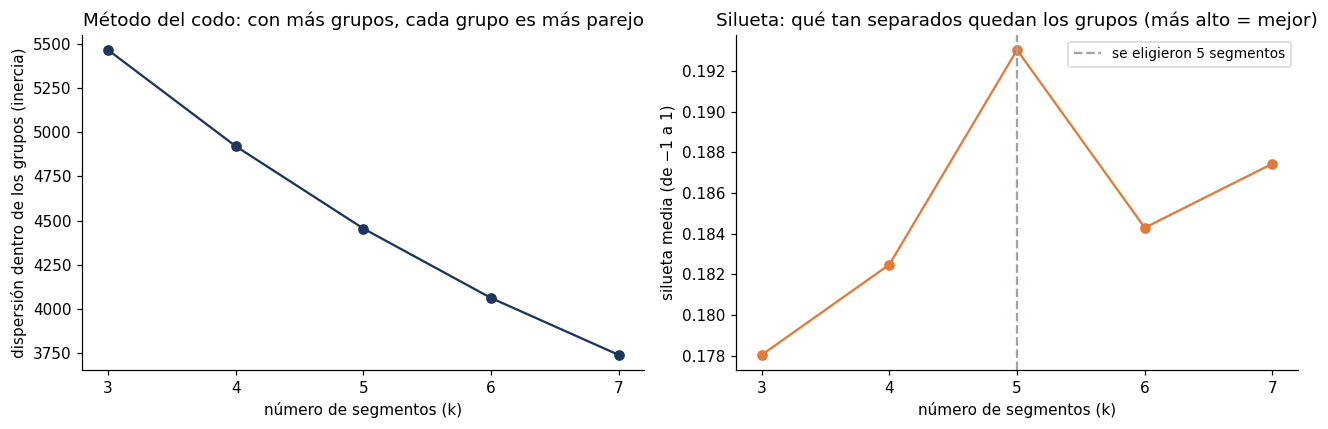

Mapa de los segmentos: las 6 variables proyectadas en 2 dimensiones (componentes principales).


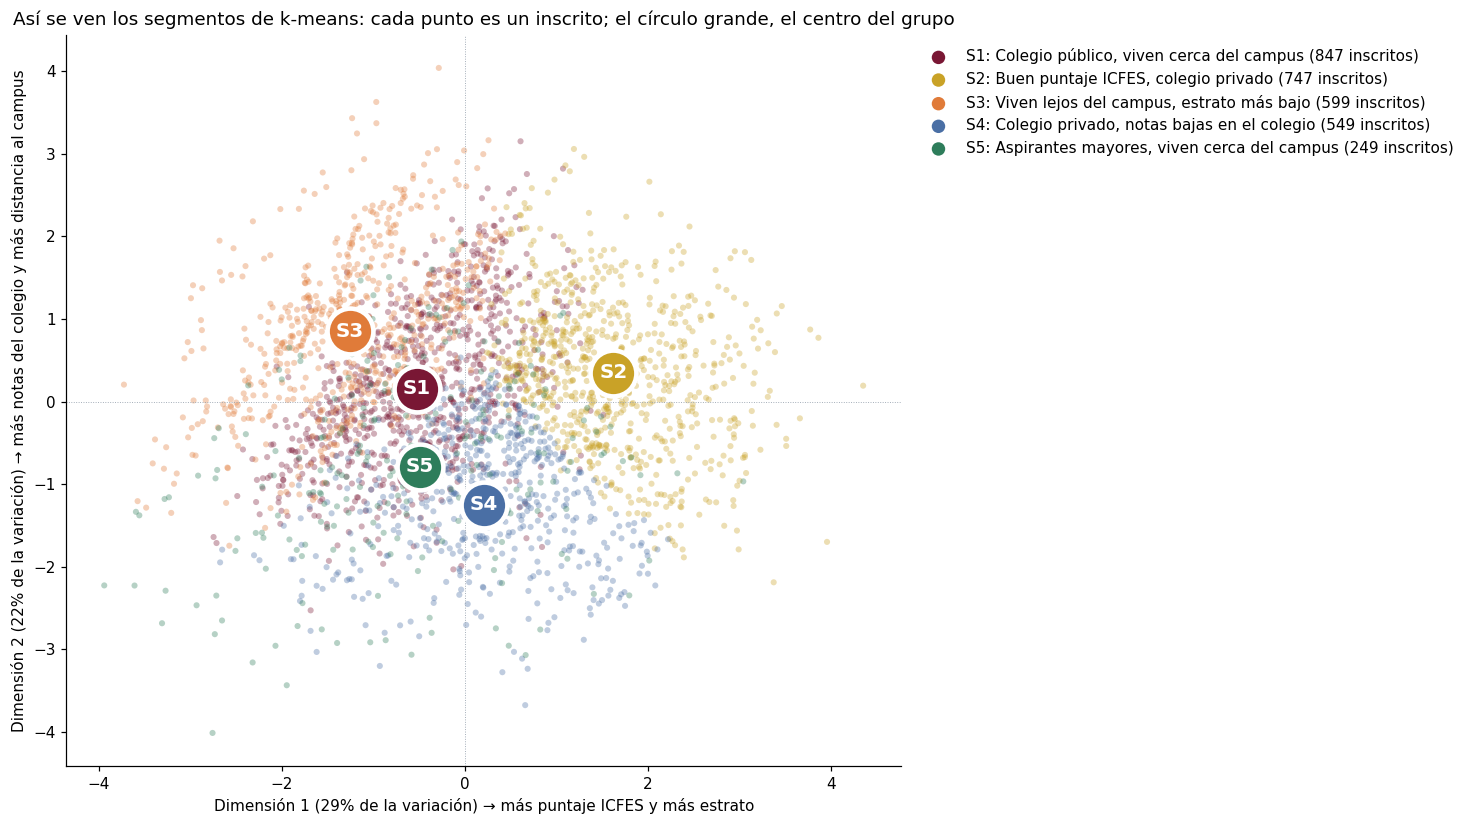

Cada segmento se nombra por los 2 rasgos en que más se aleja del promedio de los inscritos.


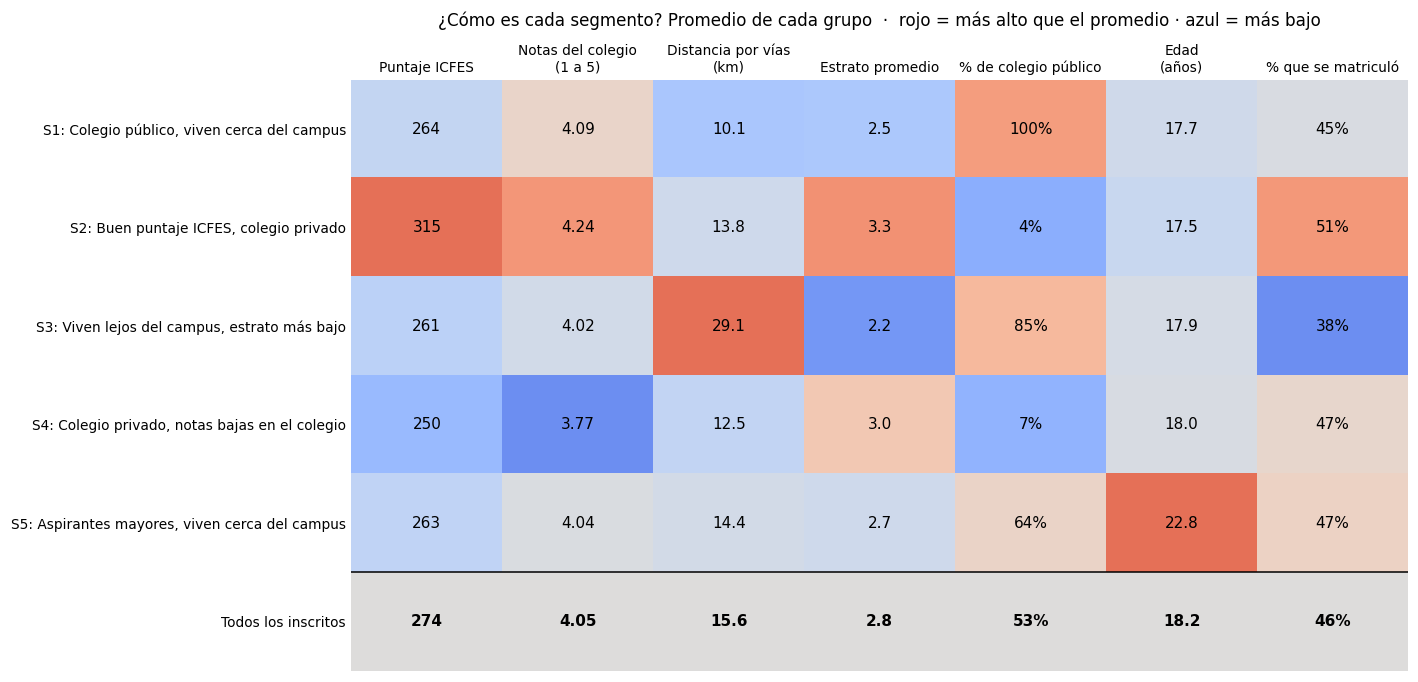

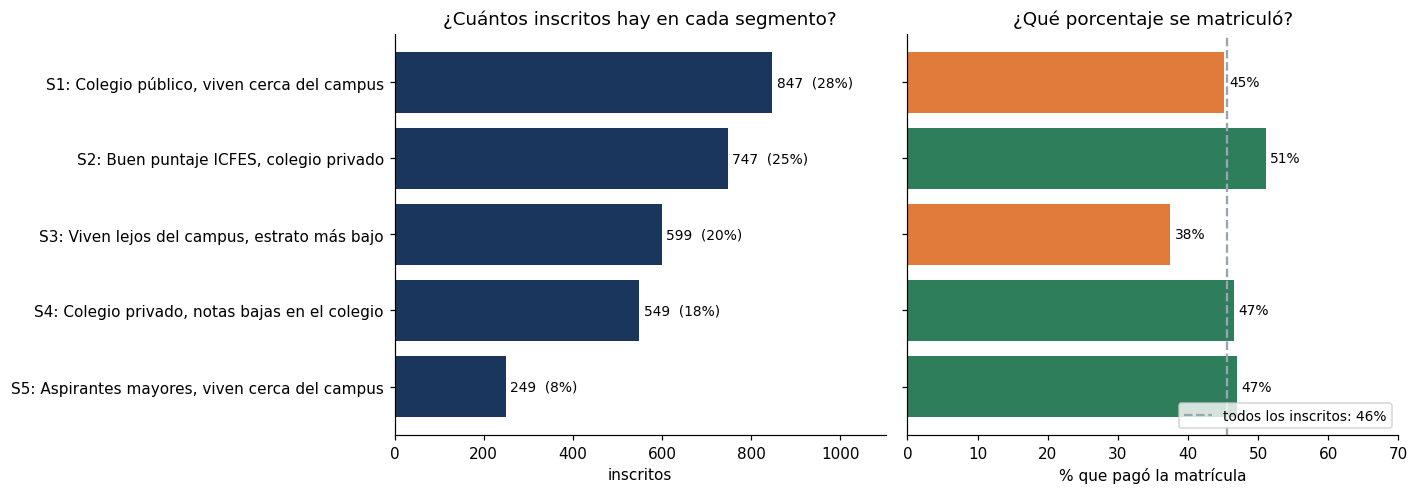

Tabla de segmentos (promedios reales de cada grupo):


,Inscritos,% del total,% que se matriculó,Puntaje ICFES,Notas del colegio (1 a 5),Distancia por vías (km),Estrato promedio,% de colegio público,Edad (años)
Segmento de mercado,,,,,,,,,
"S1: Colegio público, viven cerca del campus",847,28.300,45.200,264.000,4.090,10.100,2.500,100.000,17.700
"S2: Buen puntaje ICFES, colegio privado",747,25.000,51.100,315.000,4.240,13.800,3.300,4.000,17.500
"S3: Viven lejos del campus, estrato más bajo",599,20.000,37.500,261.000,4.020,29.100,2.200,85.000,17.900
"S4: Colegio privado, notas bajas en el colegio",549,18.400,46.600,250.000,3.770,12.500,3.000,7.000,18.000
"S5: Aspirantes mayores, viven cerca del campus",249,8.300,47.000,263.000,4.040,14.400,2.700,64.000,22.800
Todos los inscritos,2991,100.000,45.600,274.000,4.050,15.600,2.800,53.000,18.200


In [ ]:
import graficas_sprint2 as gr


def ver(fig):
    """Muestra la figura en su lugar (antes de las tablas que siguen) y la cierra."""
    display(fig)
    plt.close(fig)


ver(gr.eleccion_k(ref))
print("Mapa de los segmentos: las 6 variables proyectadas en 2 dimensiones (componentes principales).")
ver(gr.mapa_segmentos(d, ref))
print("Cada segmento se nombra por los 2 rasgos en que más se aleja del promedio de los inscritos.")
ver(gr.perfil_segmentos(d))
ver(gr.tamano_y_matricula(d))
print("Tabla de segmentos (promedios reales de cada grupo):")
display(ca.tabla_segmentos(d))

**Cómo leer el mapa.** k-means usa 6 variables a la vez, así que no se puede dibujar directamente. El mapa las resume en
2 dimensiones (componentes principales): cada punto es un inscrito, el color es el segmento que le asignó k-means y el
círculo grande es el centro del grupo. Los grupos se tocan en los bordes: por eso la silueta es baja.

**Cómo leer los nombres.** Cada segmento se nombra con los **2 rasgos en que más se diferencia del promedio**
de todos los inscritos. Los nombres son **relativos**: "viven cerca del campus" quiere decir más cerca que el promedio
(15,6 km por vías), no a menos de cierta distancia; "colegio público" quiere decir que casi todos vienen de colegios
oficiales (públicos). La tabla muestra los valores reales para comprobarlo.

| Segmento | En palabras sencillas |
|---|---|
| S1: Colegio público, viven cerca del campus | El grupo más grande: egresados de colegios públicos que viven relativamente cerca |
| S2: Buen puntaje ICFES, colegio privado | Colegios privados con el mejor ICFES (muchos aplican a la beca Saber 11); el que más se matricula |
| S3: Viven lejos del campus, estrato más bajo | Viven a unos 29 km por vías y son de estratos 1 y 2; el que menos se matricula |
| S4: Colegio privado, notas bajas en el colegio | Colegios privados con notas e ICFES por debajo del promedio |
| S5: Aspirantes mayores, viven cerca del campus | Unos 23 años en promedio: no vienen directo del colegio |

**Qué tan buenos son los grupos.** La silueta es baja (cerca de 0,2): los aspirantes no forman grupos muy separados,
algo común en datos de personas. Aun así, los segmentos tienen perfiles con sentido de negocio y tasas de matrícula
distintas (del 38% al 51%), por eso sirven para orientar la estrategia de captación (Sprint 5).

## 5. Relación de las columnas nuevas con la matrícula (entrenamiento)

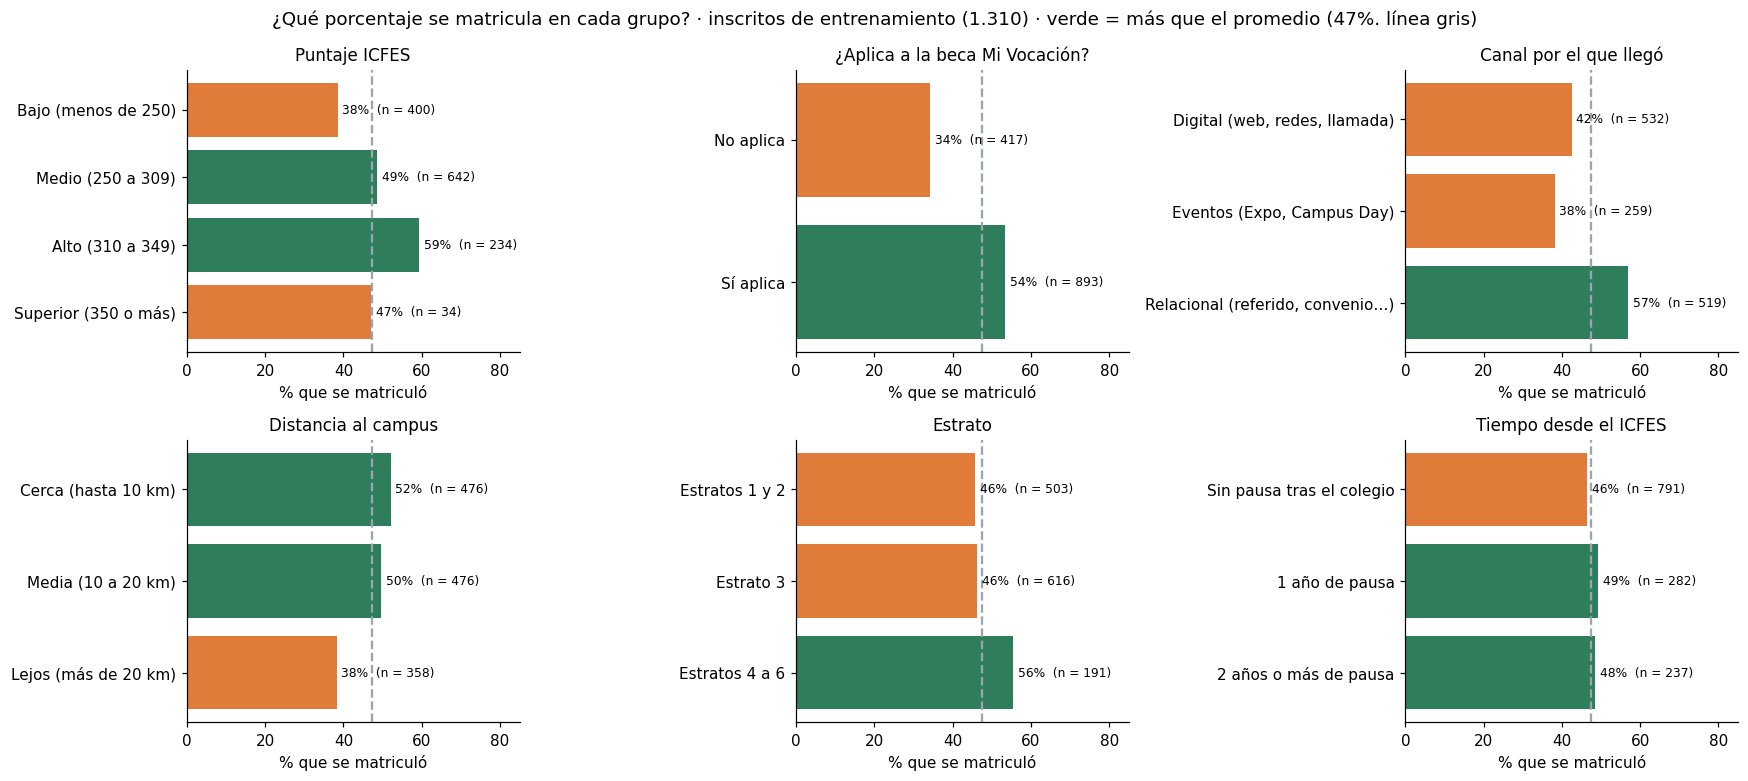

,Característica,Grupo,Inscritos,% que se matriculó
0,Puntaje ICFES,Bajo (menos de 250),400,38.500
1,Puntaje ICFES,Medio (250 a 309),642,48.600
2,Puntaje ICFES,Alto (310 a 349),234,59.400
3,Puntaje ICFES,Superior (350 o más),34,47.100
4,¿Aplica a la beca Mi Vocación?,No aplica,417,34.300
5,¿Aplica a la beca Mi Vocación?,Sí aplica,893,53.500
6,Canal por el que llegó,"Digital (web, redes, llamada)",532,42.500
7,Canal por el que llegó,"Eventos (Expo, Campus Day)",259,38.200
8,Canal por el que llegó,"Relacional (referido, convenio…)",519,57.000
9,Distancia al campus,Cerca (hasta 10 km),476,52.100


,correlación con la matrícula
"Probabilidad de recibir alguna beca según los requisitos que cumple (frecuencia histórica del entrenamiento, con suavizado de Laplace)",0.241
valor_neto_primer_semestre,-0.259
Logaritmo natural de la distancia por vías desde la dirección hasta el campus (S-44; reduce la cola larga),-0.105
z(promedio del colegio) − z(Saber 11): positivo = rinde más en el colegio que en el examen,-0.022
"Promedio esperado en el 1er semestre (regresión lineal con Saber 11, promedio del colegio y estrato bajo)",0.155


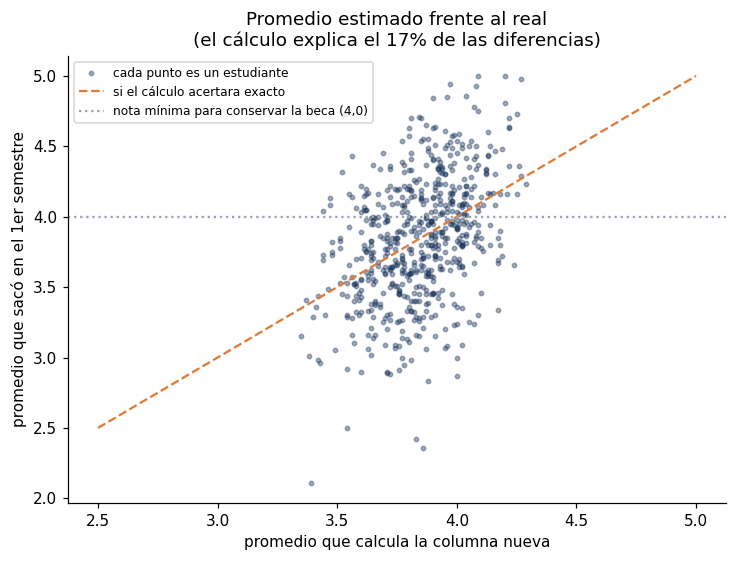

In [ ]:
ent = flujo.conjunto(d, "ENTRENAMIENTO")
columnas = ["segmento_rendimiento_icfes", "aplica_beca_mi_vocacion", "canal_agrupado", "zona_distancia", "estrato_grupo",
            "rezago_saber11"]
ver(gr.matricula_por_grupo(ent, columnas))
display(gr.tabla_matricula_por_grupo(ent, columnas))
correl = ent[["probabilidad_acceso_beca", "valor_neto_primer_semestre", "log_distancia", "brecha_colegio_vs_icfes",
              "promedio_estimado_universidad"]].corrwith(ent["matriculado"].astype(float))
display(correl.rename(ca.DICCIONARIO).round(3).rename("correlación con la matrícula").to_frame())
p_ent = flujo.conjunto(p, "ENTRENAMIENTO")     # matriculados de entrenamiento, ya con las columnas nuevas
ver(gr.promedio_estimado(p_ent, ref["regresion_promedio"]["r2"]))

**Lectura.**
- El segmento ICFES ALTO (310-349) se matricula más que el SUPERIOR (≥ 350): los puntajes muy altos tienen más
  opciones puesto a que las universidades los buscan. Es la "U invertida" que el modelo deberá captar.
- Quien aplica a Mi Vocación se matricula más: la beca baja el precio.
- Los canales relacionales (referido, inmersión, convenio) convierten más que los eventos y lo digital.
- La matrícula baja con la distancia al campus (por vías, desde la dirección de cada inscrito).

## 6. Modelo base: el "cálculo sencillo" para comparar
Para cada inscrito se predice la **tasa histórica de matrícula de su grupo** (beca × canal agrupado), aprendida en el
entrenamiento. Si un grupo tiene pocos casos, su tasa se acerca a la de su beca:

`tasa = (matriculados + m · tasa de la beca) / (inscritos + m)`, con m = 10.

Se predice "se matricula" si la tasa es ≥ 50%. El **error %** es el porcentaje de inscritos mal clasificados. Se compara
con la referencia mínima: decir siempre "no se matricula".

inscritos  matriculados  tasa_cruda  tasa_suavizada
beca        canal_agrupado                                                     
MI_VOCACION DIGITAL               170        91.000       0.535           0.539
            EVENTO                 71        35.000       0.493           0.506
            RELACIONAL            192       135.000       0.703           0.698
NINGUNA     DIGITAL               252        69.000       0.274           0.276
            EVENTO                138        39.000       0.283           0.286
            RELACIONAL            232       100.000       0.431           0.427
SABER_11    DIGITAL               110        66.000       0.600           0.599
            EVENTO                 50        25.000       0.500           0.515
            RELACIONAL             95        61.000       0.642           0.637

,n,error_pct,auc_roc,brier
Modelo base · VALIDACION,504.000,37.698,0.646,0.230
Clase mayoritaria · VALIDACION,504.000,42.460,0.500,0.247
Modelo base · PRUEBA,761.000,41.656,0.615,0.241
Clase mayoritaria · PRUEBA,761.000,44.415,0.500,0.248


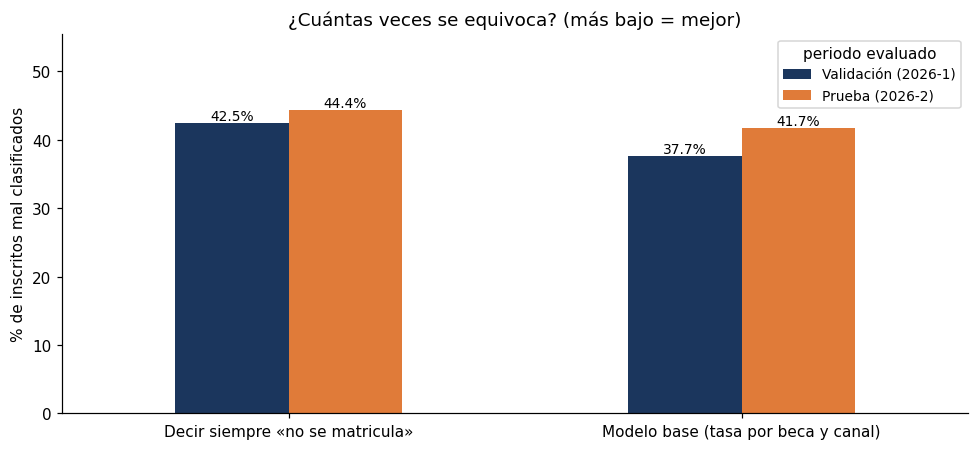


El modelo base se equivoca en el 41.7% de los inscritos de 2026-2; decir siempre 'no se matricula' se equivoca en el 44.4%. Este es el punto de comparación del Sprint 3.


In [ ]:
ent = flujo.conjunto(d, "ENTRENAMIENTO")
base = mo.ModeloBase(m=cfg["caracteristicas"]["peso_previo_modelo_base"]).fit(ent, ent["matriculado"])
mayoria = mo.ClaseMayoritaria().fit(ent, ent["matriculado"])
display(base.tabla_.round(3))
resultados = {}
for conj in ["VALIDACION", "PRUEBA"]:
    X = flujo.conjunto(d, conj)
    resultados[f"Modelo base · {conj}"] = mo.metricas(X["matriculado"], base.predict_proba(X)[:, 1])
    resultados[f"Clase mayoritaria · {conj}"] = mo.metricas(X["matriculado"], mayoria.predict_proba(X)[:, 1])
tabla = mo.tabla_metricas(resultados)
display(tabla[["n", "error_pct", "auc_roc", "brier"]])
metr = pd.DataFrame({(m, c): v for (m, c), v in [(("modelo_base" if k.startswith("Modelo") else "clase_mayoritaria",
                     k.split(" · ")[1]), v) for k, v in resultados.items()]}).T.astype(float)
ver(gr.error_modelo_base(metr))
b = resultados["Modelo base · PRUEBA"]
print(f"\nEl modelo base se equivoca en el {b['error_pct']:.1f}% de los inscritos de 2026-2; decir siempre 'no se matricula' "
      f"se equivoca en el {resultados['Clase mayoritaria · PRUEBA']['error_pct']:.1f}%. Este es el punto de comparación del Sprint 3.")